In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Part 1 - Descriptive Statistics
We describe a dataset using a few numbers: **centre** (where is the middle?) and **spread** (how scattered?).

In [2]:
df = pd.DataFrame({
    "name":        ["Arun", "Bala", "Chitra", "Divya", "Elango", "Fathima",
                    "Gokul", "Hema", "Imran", "Janani", "Karthik", "Lakshmi"],
    "dept":        ["CSE", "ECE", "CSE", "IT", "MECH", "ECE", "IT", "CSE", "MECH", "IT", "CSE", "ECE"],
    "study_hours": [4, 3, 6, 4, 2, 7, 3, 5, 1, 8, 4, 5],
    "marks":       [72, 65, 88, 70, 52, 91, 60, 82, 45, 95, 69, 76],
})
df

,name,dept,study_hours,marks
0,Arun,CSE,4,72
1,Bala,ECE,3,65
2,Chitra,CSE,6,88
3,Divya,IT,4,70
4,Elango,MECH,2,52
5,Fathima,ECE,7,91
6,Gokul,IT,3,60
7,Hema,CSE,5,82
8,Imran,MECH,1,45
9,Janani,IT,8,95


## 1.1 Measures of centre

In [3]:
marks = df["marks"]
print("Mean   :", marks.mean())      # average
print("Median :", marks.median())    # middle value when sorted
print("Mode   :", df["dept"].mode()[0])   # most frequent (here: department)

Mean   : 72.08333333333333
Median : 71.0
Mode   : CSE


If mean ≈ median, the data is roughly balanced. If they differ a lot, extreme values (outliers) are pulling the mean.
## 1.2 Measures of spread

In [4]:
print("Min      :", marks.min())
print("Max      :", marks.max())
print("Range    :", marks.max() - marks.min())
print("Variance :", round(marks.var(), 2))
print("Std dev  :", round(marks.std(), 2))   # typical distance from the mean

Min      : 45
Max      : 95
Range    : 50
Variance : 236.08
Std dev  : 15.37


## 1.3 Quartiles and IQR

In [5]:
q1 = marks.quantile(0.25)
q2 = marks.quantile(0.50)    # same as median
q3 = marks.quantile(0.75)
print("Q1 :", q1, "  Q2 :", q2, "  Q3 :", q3)
print("IQR (Q3 - Q1) :", q3 - q1)

Q1 : 63.75   Q2 : 71.0   Q3 : 83.5
IQR (Q3 - Q1) : 19.75


## 1.4 Everything at once - `describe()`

In [6]:
df[["study_hours", "marks"]].describe()

,study_hours,marks
count,12.000000,12.000000
mean,4.333333,72.083333
std,2.015095,15.365004
min,1.000000,45.000000
25%,3.000000,63.750000
50%,4.000000,71.000000
75%,5.250000,83.500000
max,8.000000,95.000000


In [7]:
print("Skewness:", round(marks.skew(), 2))   # 0 = symmetric, + = long right tail, - = long left tail

Skewness: -0.19


## 1.5 See it - histogram and boxplot

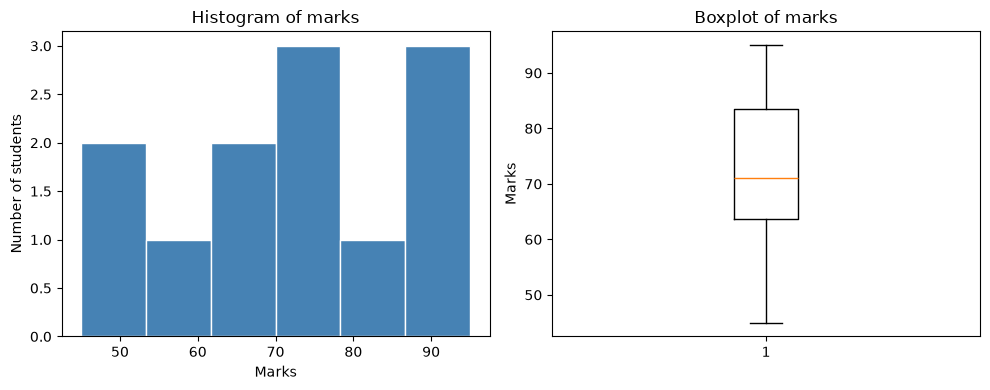

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(marks, bins=6, color="steelblue", edgecolor="white")
axes[0].set_title("Histogram of marks")
axes[0].set_xlabel("Marks")
axes[0].set_ylabel("Number of students")

axes[1].boxplot(marks)
axes[1].set_title("Boxplot of marks")
axes[1].set_ylabel("Marks")

plt.tight_layout()
plt.show()

**Reading a boxplot:** the box is Q1 to Q3 (middle 50 % of students), the orange line is the median, the whiskers show the rest, and dots (if any) are outliers.

### Try it yourself
Find the mean, median and standard deviation of `study_hours`. Draw its histogram.

In [9]:
# your code here

# Part 2 - Bivariate Analysis
*Bi* = two. Here we study how two variables move together:
**do students who study more score more?**

## 2.1 Scatter plot

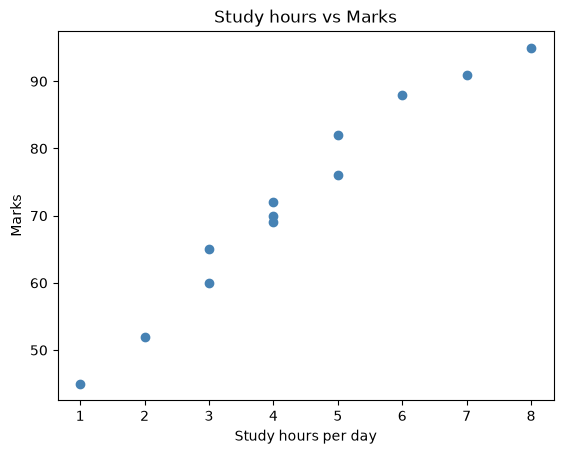

In [10]:
plt.scatter(df["study_hours"], df["marks"], color="steelblue")
plt.title("Study hours vs Marks")
plt.xlabel("Study hours per day")
plt.ylabel("Marks")
plt.show()

The points go up from left to right - a **positive** relationship. Now measure it.

## 2.2 Correlation (Pearson's r)
* r close to **+1** → strong positive
* r close to **-1** → strong negative
* r close to **0** → no linear relationship

In [11]:
r = df["study_hours"].corr(df["marks"])
print("Correlation r =", round(r, 3))

Correlation r = 0.983


In [12]:
df[["study_hours", "marks"]].corr()     # correlation matrix

,study_hours,marks
study_hours,1.000000,0.982634
marks,0.982634,1.000000


## 2.3 Best-fit line (simple regression)

marks = 7.49 x study_hours + 39.62


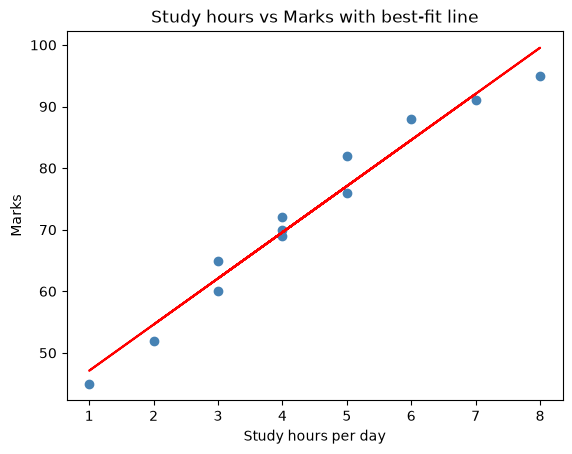

In [13]:
slope, intercept = np.polyfit(df["study_hours"], df["marks"], 1)
print(f"marks = {slope:.2f} x study_hours + {intercept:.2f}")

plt.scatter(df["study_hours"], df["marks"], color="steelblue")
plt.plot(df["study_hours"], slope * df["study_hours"] + intercept, color="red")
plt.title("Study hours vs Marks with best-fit line")
plt.xlabel("Study hours per day")
plt.ylabel("Marks")
plt.show()

**Interpretation:** each extra hour of study goes with about `slope` more marks.

⚠️ **Correlation is not causation** - a strong r says the two move together, not that one causes the other.

## 2.4 One category vs one number

In [14]:
df.groupby("dept")["marks"].mean().round(1)

dept
CSE     77.8
ECE     77.3
IT      75.0
MECH    48.5
Name: marks, dtype: float64

### Try it yourself
Which department has the highest average `study_hours`? Is the correlation between `study_hours` and `marks` stronger than 0.8?

In [15]:
# your code here

# Part 3 - Hypothesis Testing
We want to know whether a difference we see in a sample is **real** or just **luck of the sample**.

**Steps**
1. **H0 (null hypothesis)** - there is *no* difference.
2. **H1 (alternative)** - there *is* a difference.
3. Choose a significance level, **α = 0.05**.
4. Run the test and get the **p-value** = the probability of seeing a difference this big *if H0 were true*.
5. **If p < 0.05 → reject H0** (difference is statistically significant). Otherwise → fail to reject H0.

## 3.1 Independent t-test (compare **two** groups)
**Question:** a college tries a new teaching method. Do students taught with it score differently from those taught the old way?
* H0: mean marks (old) = mean marks (new)
* H1: mean marks (old) ≠ mean marks (new)

In [16]:
np.random.seed(42)    # makes the 'random' data the same every time

old_method = np.random.normal(loc=65, scale=8, size=30).round()   # average about 65
new_method = np.random.normal(loc=72, scale=8, size=30).round()   # average about 72

print("Old method mean:", old_method.mean())
print("New method mean:", new_method.mean())

Old method mean: 63.56666666666667
New method mean: 71.06666666666666


In [17]:
t_stat, p_value = stats.ttest_ind(old_method, new_method)

print("t-statistic:", round(t_stat, 3))
print("p-value    :", round(p_value, 5))

if p_value < 0.05:
    print("Reject H0 -> the two methods give significantly different marks.")
else:
    print("Fail to reject H0 -> no significant difference.")

t-statistic: -3.956
p-value    : 0.00021
Reject H0 -> the two methods give significantly different marks.


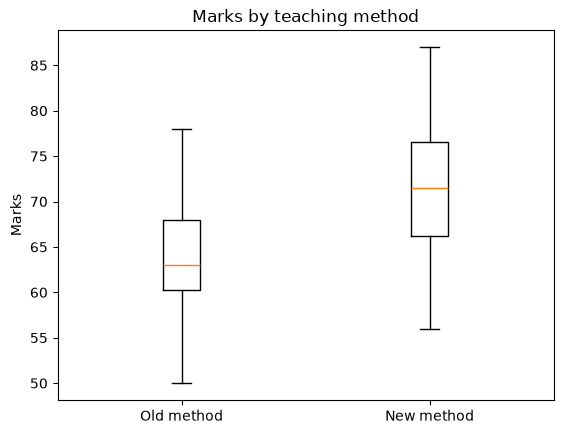

In [18]:
plt.boxplot([old_method, new_method], tick_labels=["Old method", "New method"])
plt.title("Marks by teaching method")
plt.ylabel("Marks")
plt.show()

## 3.2 One-way ANOVA (compare **three or more** groups)
Why not many t-tests? Every extra test increases the chance of a false alarm. ANOVA checks all groups in **one** test.

**Question:** do students of CSE, ECE and MECH have different average marks?
* H0: all three department means are equal
* H1: at least one department mean is different

In [19]:
np.random.seed(7)

cse  = np.random.normal(loc=75, scale=7, size=25).round()
ece  = np.random.normal(loc=70, scale=7, size=25).round()
mech = np.random.normal(loc=62, scale=7, size=25).round()

print("CSE mean :", cse.mean())
print("ECE mean :", ece.mean())
print("MECH mean:", mech.mean())

CSE mean : 75.4
ECE mean : 68.36
MECH mean: 62.28


In [20]:
f_stat, p_value = stats.f_oneway(cse, ece, mech)

print("F-statistic:", round(f_stat, 3))
print("p-value    :", f"{p_value:.2e}")

if p_value < 0.05:
    print("Reject H0 -> at least one department is different.")
else:
    print("Fail to reject H0 -> no significant difference between departments.")

F-statistic: 18.988
p-value    : 2.38e-07
Reject H0 -> at least one department is different.


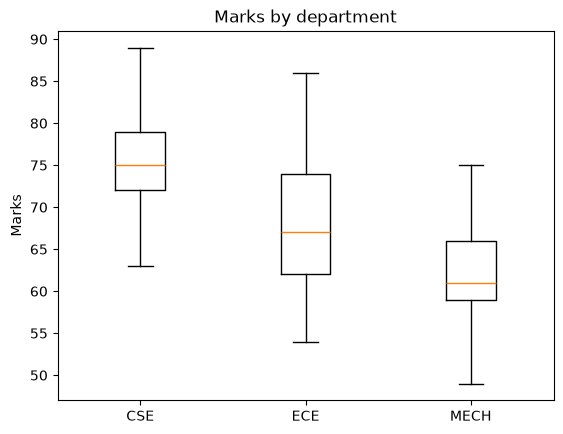

In [21]:
plt.boxplot([cse, ece, mech], tick_labels=["CSE", "ECE", "MECH"])
plt.title("Marks by department")
plt.ylabel("Marks")
plt.show()

ANOVA only says *some* department differs, not *which*. The boxplot hints at it (MECH looks lowest). A follow-up (post-hoc) test such as Tukey's HSD finds the exact pair.

### Try it yourself
1. Change the new-method mean from 72 to 66. Does the t-test still reject H0? Why?
2. Make all three department means equal (e.g. 70). What does ANOVA say now?

In [22]:
# your code here

# Cheat sheet
| Question | Tool | Code |
|---|---|---|
| Typical value of a column? | mean / median | `s.mean()`, `s.median()` |
| How spread out? | std, IQR | `s.std()`, `q3 - q1` |
| Quick overview | describe | `df.describe()` |
| Do two numbers move together? | correlation + scatter | `a.corr(b)`, `plt.scatter` |
| Do 2 group means differ? | t-test | `stats.ttest_ind(a, b)` |
| Do 3+ group means differ? | one-way ANOVA | `stats.f_oneway(a, b, c)` |
| Decision rule | p-value | `p < 0.05` → reject H0 |